In [1]:

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive5')

PROJECT = Path("/content/drive5/MyDrive/Ocular_Project")
RESULTS = PROJECT / "results/IITD"
MODELS = PROJECT / "models/IITD"
OUT_DIR = RESULTS / "notebook15_final_demo"
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert PROJECT.exists(), f"Project not found: {PROJECT}"

print("=" * 60)
print("NOTEBOOK 15 — FINAL DEPLOYMENT AND DEMO")
print("=" * 60)
print("Execution: CPU-friendly; no training")
print("Output:", OUT_DIR)

checks = {
    "Recognition comparison": RESULTS / "notebook10_recognition_augmented/IITD_recognition_augmented_comparison.csv",
    "GAN vs diffusion comparison": RESULTS / "notebook11_gan_vs_diffusion/IITD_GAN_vs_Diffusion_summary.json",
    "Membership inference results": RESULTS / "notebook12_membership_inference/IITD_membership_attack_metrics.csv",
    "Notebook 14 summary": RESULTS / "notebook14_visualization_ablation/IITD_notebook14_consolidated_summary.json",
    "Baseline checkpoint": MODELS / "IITD_baseline_resnet18_best.pth",
}

for name, path in checks.items():
    print(f"{'FOUND' if path.is_file() else 'MISSING'} | {name} | {path.name}")


Mounted at /content/drive5
NOTEBOOK 15 — FINAL DEPLOYMENT AND DEMO
Execution: CPU-friendly; no training
Output: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook15_final_demo
FOUND | Recognition comparison | IITD_recognition_augmented_comparison.csv
FOUND | GAN vs diffusion comparison | IITD_GAN_vs_Diffusion_summary.json
FOUND | Membership inference results | IITD_membership_attack_metrics.csv
FOUND | Notebook 14 summary | IITD_notebook14_consolidated_summary.json
FOUND | Baseline checkpoint | IITD_baseline_resnet18_best.pth


Baseline model loaded successfully.
Device: cpu
Output classes: 425

Upload one eye image to run the demo.


Saving 01_L.bmp to 01_L.bmp


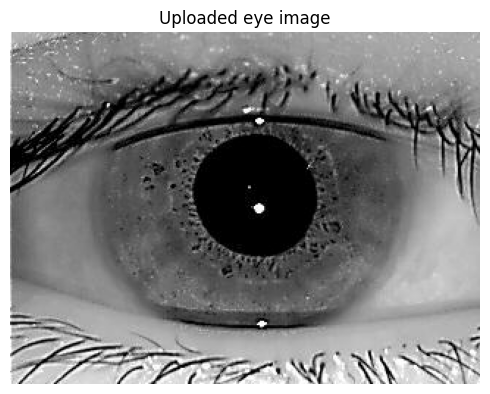

EXPERIMENTAL OCULAR RECOGNITION DEMO
File: 01_L.bmp
Predicted dataset class: 006_R
Model confidence: 9.39%

Top predictions:


,dataset_class,model_confidence
0,006_R,0.0939
1,149_L,0.0885
2,002_L,0.0833
3,065_L,0.0479
4,122_L,0.0459



Important: this prediction is a model output, not a verified person's identity. Confidence is not a calibrated probability of identity correctness.

Prediction summary saved to Drive.


In [2]:

import json
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from IPython.display import display
from google.colab import files
from torchvision import models, transforms

# ---------------------------------------------------------
# 1. Load saved baseline model (CPU only)
# ---------------------------------------------------------
DEVICE = torch.device("cpu")
CHECKPOINT = MODELS / "IITD_baseline_resnet18_best.pth"
MANIFEST = RESULTS / "notebook09_dataset_augmentation/IITD_original_split_manifest.csv"

manifest = pd.read_csv(MANIFEST)
num_classes = int(manifest["label"].max()) + 1

model = models.resnet18(weights=None)
model.conv1 = nn.Conv2d(
    1, 64, kernel_size=7, stride=2, padding=3, bias=False
)
model.fc = nn.Linear(model.fc.in_features, num_classes)

checkpoint = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=False
)
if "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]
elif "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]

if any(k.startswith("module.") for k in checkpoint):
    checkpoint = {
        k.replace("module.", "", 1): v for k, v in checkpoint.items()
    }

model.load_state_dict(checkpoint)
model.eval()

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Map numeric model classes to manifest labels
class_names = (
    manifest[["label", "label_name"]]
    .drop_duplicates()
    .sort_values("label")
    .set_index("label")["label_name"]
    .to_dict()
)

print("Baseline model loaded successfully.")
print("Device:", DEVICE)
print("Output classes:", num_classes)
print("\nUpload one eye image to run the demo.")

# ---------------------------------------------------------
# 2. Upload image and run inference
# ---------------------------------------------------------
uploaded = files.upload()

if not uploaded:
    print("No image uploaded. Run this cell again to try.")
else:
    filename = next(iter(uploaded))
    image_path = Path(filename)

    try:
        with Image.open(image_path) as im:
            original = im.convert("RGB")
            model_input = transform(original).unsqueeze(0)

        with torch.inference_mode():
            logits = model(model_input)
            probabilities = torch.softmax(logits, dim=1)[0]
            top_probs, top_indices = torch.topk(
                probabilities, k=min(5, num_classes)
            )

        predicted_index = int(top_indices[0])
        predicted_class = class_names.get(
            predicted_index, f"class_{predicted_index}"
        )
        confidence = float(top_probs[0])

        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(original)
        ax.set_title("Uploaded eye image")
        ax.axis("off")
        plt.tight_layout()
        plt.show()
        plt.close(fig)

        print("=" * 55)
        print("EXPERIMENTAL OCULAR RECOGNITION DEMO")
        print("=" * 55)
        print("File:", filename)
        print("Predicted dataset class:", predicted_class)
        print(f"Model confidence: {confidence:.2%}")
        print("\nTop predictions:")

        top_rows = []
        for idx, prob in zip(top_indices.tolist(), top_probs.tolist()):
            top_rows.append({
                "dataset_class": class_names.get(idx, f"class_{idx}"),
                "model_confidence": round(float(prob), 4)
            })

        display(pd.DataFrame(top_rows))

        print(
            "\nImportant: this prediction is a model output, not a "
            "verified person's identity. Confidence is not a calibrated "
            "probability of identity correctness."
        )

        demo_record = {
            "uploaded_filename": filename,
            "predicted_dataset_class": predicted_class,
            "model_confidence": confidence,
            "top_predictions": top_rows,
            "model_checkpoint": CHECKPOINT.name,
            "device": "cpu",
            "identity_verified": False
        }

        with open(OUT_DIR / "IITD_demo_last_prediction.json", "w") as f:
            json.dump(demo_record, f, indent=2)

        print("\nPrediction summary saved to Drive.")

    except Exception as e:
        print("Could not process this file:", repr(e))
        print("Please upload a valid image file.")


In [3]:

import json

expected = [
    OUT_DIR / "IITD_demo_last_prediction.json",
]

print("NOTEBOOK 15 — FINAL VERIFICATION")
for path in expected:
    print(f"{'OK' if path.is_file() else 'MISSING'} | {path.name}")

if expected[0].is_file():
    with open(expected[0]) as f:
        demo = json.load(f)
    print("Prediction record valid:", bool(demo.get("predicted_dataset_class")))
    print("Device:", demo.get("device"))
    print("Identity verified:", demo.get("identity_verified"))

print("\nNo model training performed.")


NOTEBOOK 15 — FINAL VERIFICATION
OK | IITD_demo_last_prediction.json
Prediction record valid: True
Device: cpu
Identity verified: False

No model training performed.



# Final Project Conclusion

## Project Overview
This project explored synthetic ocular image generation using traditional augmentation, a conditional GAN, and an unconditional diffusion model, alongside ocular recognition and exploratory privacy analysis on the IIT Delhi dataset.

## Implementation
- Collected and analyzed the dataset.
- Preprocessed ocular images and assessed image quality.
- Built a baseline ResNet18 recognition model.
- Evaluated traditional augmentation, GAN-generated samples, and diffusion-generated samples.
- Compared low-level image statistics and recognition results.
- Conducted an exploratory membership-inference attack and consolidated the findings.
- Implemented a CPU-compatible demonstration using the saved baseline model.

## Final Demonstration
The demonstration accepts an uploaded eye image, preprocesses it, and displays the model's top-five predicted dataset classes and associated model confidence scores. No additional model training is performed.

## Limitations
The experiments are exploratory. Recognition runs used limited training epochs, generated samples were not verified as preserving biometric identity, and the privacy attack results do not prove the presence or absence of privacy leakage. Model confidence is not a calibrated probability of identity correctness.

## Conclusion
The project establishes an experimental pipeline for ocular image preprocessing, synthetic data exploration, recognition evaluation, and privacy analysis. More controlled experiments, stronger generative models, identity-preservation evaluation, and rigorous privacy testing are required before practical biometric deployment.
